In [47]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label

from forest_fire import model_step, run_model

In [48]:
# parameters
n = 100
p = 0.001
ratio = 70      # this is the ratio used by the original paper
seed = 42       # random seed for reproducibility

# initialisation
L = np.zeros((n, n))
rng = np.random.default_rng(seed)

In [49]:
steps = 1500
f = p / ratio
densities = []

for t in range(steps):
    L = model_step(L, n, p, f, rng)
    densities.append(np.mean(L == 1))

We will start capturing snaphots of the forest only after it develops, i.e. the forest density passes the initial growth phase.

C:\Users\Simona\AppData\Local\Temp\ipykernel_17200\1805103233.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


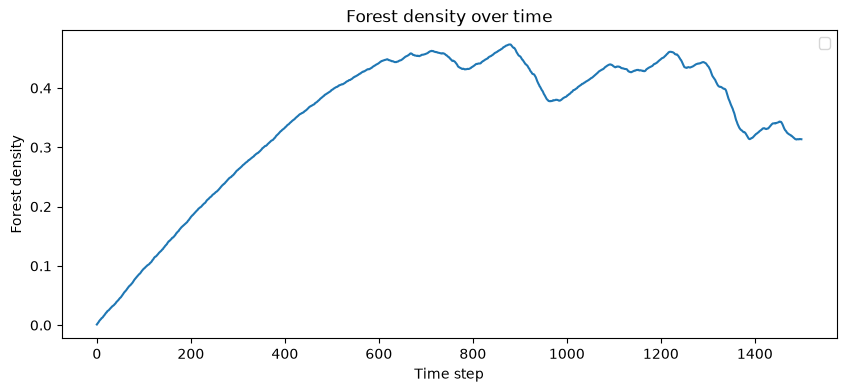

In [50]:
plt.figure(figsize=(10, 4))

plt.plot(densities)

plt.xlabel("Time step")
plt.ylabel("Forest density")
plt.title("Forest density over time")

plt.legend()
plt.show()

We see that the forest desnisty stops its initial growth phase around the 650th timestep, so we will select it as the burn-in period.

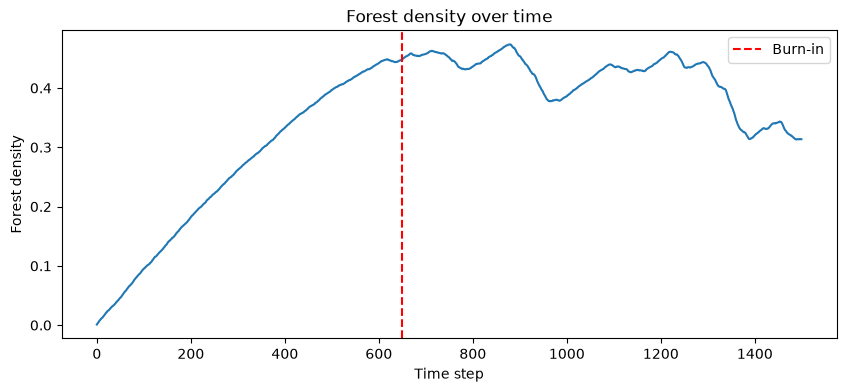

In [51]:
burnin = 650       # from the plot above, this timesteps seems to be a good burn-in period
plt.figure(figsize=(10, 4))

plt.plot(densities)

plt.xlabel("Time step")
plt.ylabel("Forest density")
plt.axvline(burnin, color="red", linestyle="--", label="Burn-in")
plt.title("Forest density over time")

plt.legend()
plt.show()

In [52]:
# four-neighbor connectivity (up, down, left, right) used to identify clusters
structure = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
])

def get_cluster_sizes(L):
    # identify connected clusters of trees
    clusters, n_clusters = label(L == 1, structure = structure)     # we are only counting living trees (cells that are equal to 1)

    # count trees in each cluster
    counts = np.bincount(clusters.ravel())

    # exclude label 0 (empty and burning cells)
    cluster_sizes = counts[1:]

    return cluster_sizes

In [53]:
# reset the lattice and random generator
L = np.zeros((n, n))
rng = np.random.default_rng(seed)

# burn-in
L = run_model(L, n, p, f, 600, rng)

We will rerun the model for 10_000 timesteps to get a representative average of `N(s)`, and collect cluster sizes every 50 steps which gives us 200 snaphots that we will average.

In [54]:
sampling_steps = 10_000
sampling_interval = 50

all_cluster_sizes = []

for t in range(sampling_steps):
    L = model_step(L, n, p, f, rng)

    if t % sampling_interval == 0:
        sizes = get_cluster_sizes(L)
        all_cluster_sizes.extend(sizes)

In [55]:
counts = np.bincount(all_cluster_sizes)     # count clusters of each size

s = np.arange(1, len(counts))       # array of possible cluster sizes
N_s = counts[1:] / (sampling_steps // sampling_interval)    # we exclude cluster size 0

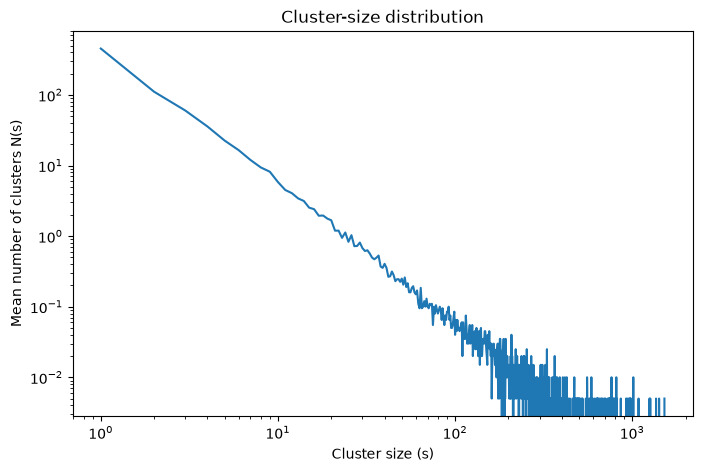

In [56]:
plt.figure(figsize=(8, 5))

plt.loglog(s, N_s, "-", markersize=3)

plt.xlabel("Cluster size (s)")
plt.ylabel("Mean number of clusters N(s)")
plt.title("Cluster-size distribution")

plt.show()

In [57]:
# select a fitting range
mask = (s >= 1) & (s <= 100) & (N_s > 0)

# fit a straight line in log-log space
slope, intercept = np.polyfit(
    np.log10(s[mask]),
    np.log10(N_s[mask]),
    1
)

tau = -slope

print(f"Estimated exponent: {tau:.3f}")

Estimated exponent: 2.003
